<h1 align="center">Práctica 5A. Divide y vencerás (sesión 1)</h1>
<h3 style="display:block; margin-top:5px;" align="center">Estructuras de datos</h3>
<h3 style="display:block; margin-top:5px;" align="center">2026-2027</h3>
<h3 style="display:block; margin-top:5px;" align="center">Universitat Politècnica de València</h3>
<br>

**Pon/poned aquí tú/vuestros nombre(s):**
> Aleksey Odnokoubov

## Introducción: Buscar el elemento que no se repite

Nos dan un vector **ordenado** donde todos los elementos, menos uno, aparecen repetidos dos veces. Por ejemplo, en el siguiente vector:

```python
v = [12, 12, 20, 20, 25, 30, 30, 45, 45, 70, 70]
#     0   1   2   3   4   5   6   7   8   9  10
```

el elemento `25` es el único que no aparece repetido 2 veces (aparece en el índice 4).

El objetivo de la práctica es comparar dos estrategias para encontrar el único elemento no repetido.

Ejecuta la siguiente celda para disponer de funciones para generar muestras y para probar una batería de test:

In [2]:
import random

# generamos un vector de manera aleatoria:
def generar_instancia(longitud):
    pos = random.randrange(longitud)
    x = random.randrange(100)
    v = []
    for i in range(longitud):
        x += random.randrange(1,10)
        v.extend([x,x])
        if i==pos:
            elem = v.pop()
    return v,elem

print("Ejemplo de salida de generar_instancia")
print(generar_instancia(5))

def probar_bateria_test( funcion, pruebas=20 ):
    bateria = [([12, 12, 20, 20, 25, 30, 30, 45, 45, 70, 70],25),
               ([5,7,7,9,9,20,20,30,30],5),
               ([5,5,7,7,9,9,20,20,30],30),
               ([5,5,7,9,9,20,20,30,30],7),
               ([5,5,7,7,9,9,20,30,30],20)]

    for i in range(pruebas):
        v, elem = bateria[i] if i<len(bateria) else generar_instancia(50)
        resul = funcion(v)
        if resul == elem:
            print(f'test {i+1:2d}/{pruebas} passed')
        else:
            print(f'test {i+1:2d}/{pruebas} FAILED')
            break
    else:
        print("All tests passed succesfully :)")

Ejemplo de salida de generar_instancia
([76, 76, 79, 79, 83, 86, 86, 94, 94], 83)


## Actividad 1: Implementación iterativa (que NO es divide y vencerás)

En esta primera actividad debes implementar una función iterativa que encuentre el elemento sin repetir:

- Asume que el vector contiene números enteros ordenados y con todos duplicados menos uno. Como mínimo tiene longitud 1.
- ¿Es posible que el elemento sin repetir ocupe un índice impar? Razona la respuesta.
- Recorre el vector avanzando **de 2 en 2** hasta encontrar un elemento que sea distinto al siguiente. Si no lo encuentras es que el elemento distinto será el último del vector.
- ¿Cuál es el coste de la función implementada?

In [3]:
def sin_repetir_iterativo(v):
    for index in range(0, len(v) - 1, 2):
        if v[index] != v[index + 1]:
            return v[index]

    return v[-1]

La siguiente función nos sirve para probar unos cuantos casos:

In [4]:
probar_bateria_test(sin_repetir_iterativo)

test  1/20 passed
test  2/20 passed
test  3/20 passed
test  4/20 passed
test  5/20 passed
test  6/20 passed
test  7/20 passed
test  8/20 passed
test  9/20 passed
test 10/20 passed
test 11/20 passed
test 12/20 passed
test 13/20 passed
test 14/20 passed
test 15/20 passed
test 16/20 passed
test 17/20 passed
test 18/20 passed
test 19/20 passed
test 20/20 passed
All tests passed succesfully :)


## Actividad 2: Resolución tipo DyV

El objetivo de esta actividad es implementar una función que, **utilizando la técnica de divide y vencerás (DyV)**, encuentre el valor no repetido con coste $O(\log n)$.

Para ello se dan las siguientes pistas:

- Se basa en la búsqueda dicotómica. **NO utilices slices**, hay que utilizar índices posicionales (por ejemplo `first` y `last`). Se asume en todo momento que el elemento único se encuentra entre las posiciones `first` y `last` inclusive.
- Es muy **importante** (en cualquier ejercicio tipo búsqueda dicotómica) no salirse del vector. En particular, Python no siempre dará error si accedes con un índice negativo (te sales por la izquierda), con lo que es posible que el programa **esté mal sin que dé error**.
- Si te sitúas en una posición cualquiera del vector ¿se te ocurre alguna forma de determinar si el elemento que no está repetido está en esa posición, a su izquierda o a su derecha?
- Puedes tratar como casos especiales:
    - Un vector de talla 1.
    - El elemento sin repetir es el primero del vector.
    - El elemento sin repetir es el último del vector.
    
  De esa forma, el caso general puede ir desde el segundo hasta el penúltimo y así poder acceder a `v[middle-1]` o a `v[middle+1]` sin miedo a salirte de los límites del vector.  

- Para poder determinar en qué lado está el elemento sin repetir se aconseja analizar los índices de las parejas de valores antes y después del elemento único.

    Volviendo al ejemplo de la introducción (acompañado de los índices del vector):

    ```python
    v = [12, 12, 20, 20, 25, 30, 30, 45, 45, 70, 70]
    #     0   1   2   3   4   5   6   7   8   9  10
    ```

    Las parejas ANTES del elemento único son:

    - 12,12 en los índices 0,1 (índice par, índice impar)
    - 20,20 en los índices 2,3 (índice par, índice impar)

    Las parejas DESPUÉS del elemento único son:

    - 30,30 en los índices 5,6 (índice impar, índice par)
    - 45,45 en los índices 7,8 (índice impar, índice par)
    - 70,70 en los índices 9,10 (índice impar, índice par)

Con todas estas pistas, completa el siguiente código de tipo DyV:

In [5]:
def sin_repetir_DyV(v):
    first = 0
    last = len(v) - 1

    while first < last:
        mid = (first + last) // 2

        if mid % 2 == 1:
            mid -= 1

        if v[mid] == v[mid + 1]:
            first  = mid + 2
        else:
            last = mid

    return v[first]

La siguiente llamada comprueba que la función pasa la batería de tests anterior:

In [6]:
probar_bateria_test(sin_repetir_DyV)

test  1/20 passed
test  2/20 passed
test  3/20 passed
test  4/20 passed
test  5/20 passed
test  6/20 passed
test  7/20 passed
test  8/20 passed
test  9/20 passed
test 10/20 passed
test 11/20 passed
test 12/20 passed
test 13/20 passed
test 14/20 passed
test 15/20 passed
test 16/20 passed
test 17/20 passed
test 18/20 passed
test 19/20 passed
test 20/20 passed
All tests passed succesfully :)


## Actividad 3 Comparar tiempos de ejecución

El objetivo de esta actividad es comparar de manera experimental el tiempo medio de ejecución de las dos soluciones desarrolladas y obtener una gráfica para distintas tallas.

Se muestran las gráficas con y sin ajuste de curvas. La interesante es con ajuste de curvas, pero si no tienes instalado scipy o numpy basta con probar la primera opción.

Debes completar el siguiente código para que realice la medida de tiempos de la función de `sin_repetir_DyV`:

In [ ]:
import time

veces = 200
talla_max = 10_000

tallas, iterativo, dyv = [], [],[]
for talla in range(500, talla_max+1, 500):
    tallas.append(talla)
    t_dyv  = 0
    muestras = [generar_instancia(talla) for _ in range(veces)]
    
    tini = time.perf_counter()
    for v, elem in muestras:
        resul = sin_repetir_iterativo(v)
        if resul != elem:
            print("Algo no ha ido bien en el iterativo")
            break
    tfin = time.perf_counter()
    iterativo.append((tfin-tini)/veces)


    tini = time.perf_counter()
    for v, elem in muestras:
        resul = sin_repetir_DyV(v)
        if resul != elem:
            print('Algo no ha ido bien en el iterativo')
            break

    tfin = time.perf_counter()
    dyv.append((tfin-tini)/veces)


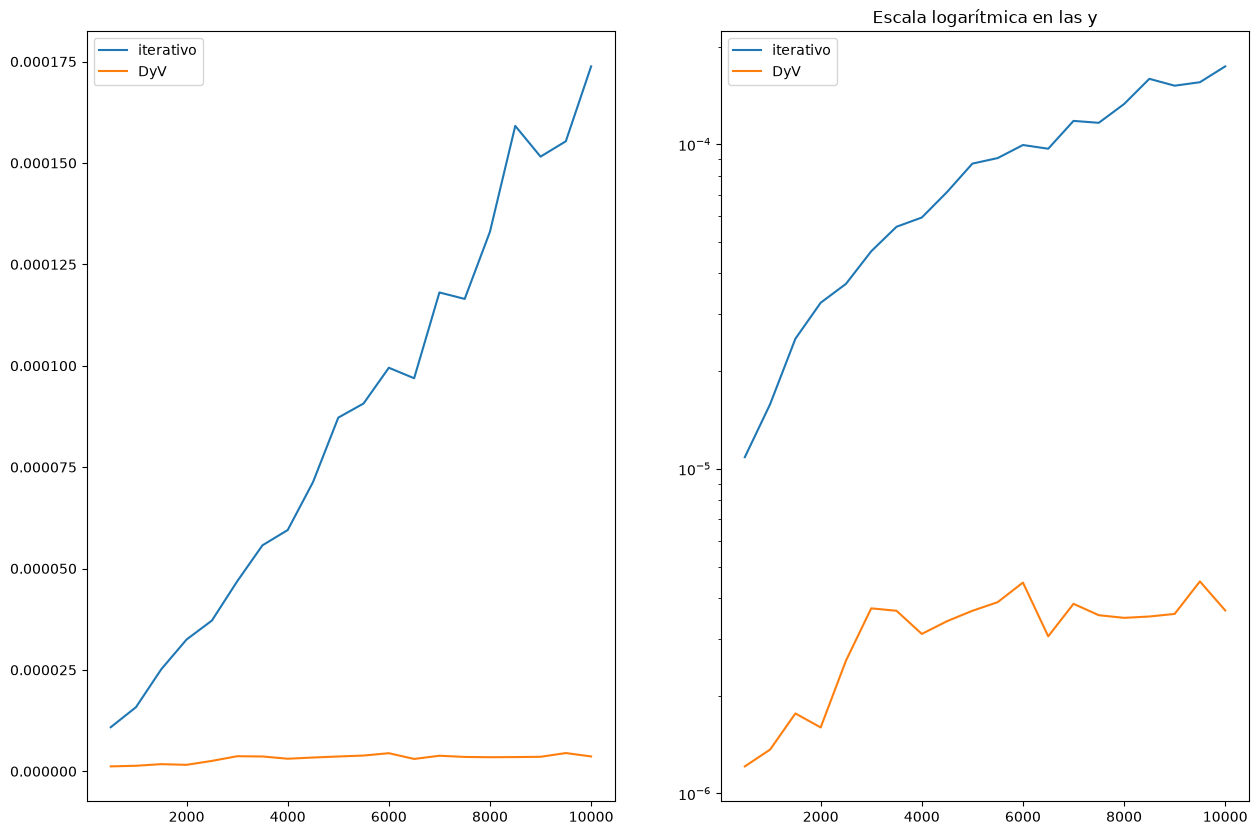

In [8]:
# mostrar la gráfica de los tiempos:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(ncols=2, figsize=(15,10))
ax[0].plot(tallas, iterativo, label='iterativo')
ax[0].plot(tallas, dyv, label='DyV')
ax[0].legend(loc='upper left')

ax[1].set_title('Escala logarítmica en las y')
ax[1].set_yscale('log')
ax[1].plot(tallas, iterativo, label='iterativo')
ax[1].plot(tallas, dyv, label='DyV')
ax[1].legend(loc='upper left')
plt.show()

In [11]:
%pip install scipy

  Using cached scipy-1.18.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
Using cached scipy-1.18.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)
Note: you may need to restart the kernel to use updated packages.


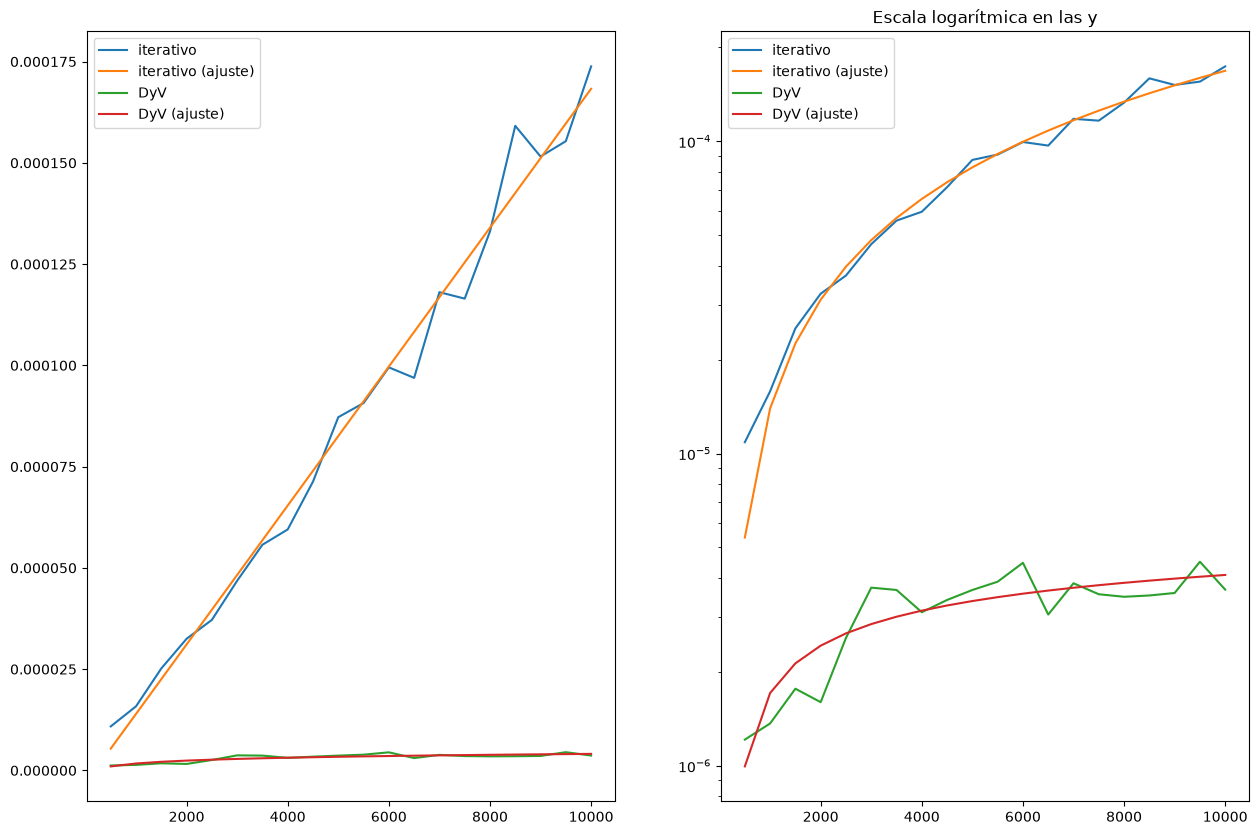

In [12]:
# mostrar las mismas gráficas con ajuste de curvas
# ATENCION: necesita utilizar scipy, puede que no lo tengas instalado (no pasa nada)

import scipy.optimize as opt
import numpy as np

def linear(x, a, b):
    return a * x + b

def logn(x, a, b):
     return a * np.log(x) + b

# Obtenemos los parámetros de la función lineal que mejor se ajuste a los puntos x,y
params_linear, cov = opt.curve_fit(linear, tallas, iterativo)
yfit_linear = linear(np.array(tallas), *params_linear)

# Obtenemos los parámetros de la función logn que mejor se ajuste a los puntos x,y
params_dyv, cov = opt.curve_fit(logn, tallas, dyv)
yfit_dyv = logn(np.array(tallas), *params_dyv)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(ncols=2, figsize=(15,10))
ax[0].plot(tallas, iterativo, label='iterativo')
ax[0].plot(tallas, yfit_linear, label='iterativo (ajuste)')
ax[0].plot(tallas, dyv, label='DyV')
ax[0].plot(tallas, yfit_dyv, label='DyV (ajuste)')
ax[0].legend(loc='upper left')

ax[1].set_yscale('log')
ax[1].set_title('Escala logarítmica en las y')
ax[1].plot(tallas, iterativo, label='iterativo')
ax[1].plot(tallas, yfit_linear, label='iterativo (ajuste)')
ax[1].plot(tallas, dyv, label='DyV')
ax[1].plot(tallas, yfit_dyv, label='DyV (ajuste)')

ax[1].legend(loc='upper left')
plt.show()